# Цель работы

Реализовать и проверить алгоритм нечёткого вывода Мамдани для модели ИБП из лабораторной работы 4.

# Задачи

Выполнить фаззификацию, конъюнкцию min, отсечение выходных термов, объединение max и дефаззификацию методом центра тяжести.

# Ход работы

Модель и 27 правил импортируются из `../lab-4/fuzzy.py`. Входы за пределами заданных диапазонов отклоняются. Степень активации правила равна минимуму степеней его предпосылок. Итоговая функция принадлежности — максимум усечённых выходных функций. Численный центр тяжести вычисляется интегрированием методом трапеций.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "lab-4"))
from fuzzy import membership, output_terms, domains, rules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
def mamdani(power, time, noise):
    values = {"power": power, "time": time, "noise": noise}
    for name, value in values.items():
        lo, hi = domains[name]
        if not np.isfinite(value) or not lo <= value <= hi:
            raise ValueError(f"{name}: значение вне диапазона [{lo}, {hi}]")
    degrees = {name: {term: float(fn(values[name])) for term, fn in terms.items()}
               for name, terms in membership.items()}
    x = np.linspace(0, 100, 2001)
    aggregate = np.zeros_like(x)
    active = []
    for p, t, n, output in rules:
        alpha = min(degrees["power"][p], degrees["time"][t], degrees["noise"][n])
        if alpha > 0:
            aggregate = np.maximum(aggregate, np.minimum(alpha, output_terms[output](x)))
            active.append((p,t,n,output,alpha))
    area = np.trapezoid(aggregate, x)
    if area <= 0: raise ValueError("Нет активных правил")
    centroid = np.trapezoid(x * aggregate, x) / area
    return centroid, x, aggregate, active


## Проверка системы

In [3]:
#| tbl-cap: "Численные рейтинги учебных конфигураций ИБП"
supplies = [("A",390,1,60), ("B",900,2.5,47), ("C",2700,5,40),
            ("D",660,1.7,45), ("E",6000,15,0), ("F",0,0,70)]
results = [(name,p,t,n,mamdani(p,t,n)[0]) for name,p,t,n in supplies]
pd.DataFrame(results, columns=["ИБП","Вт","мин","дБ","Рейтинг"])


,ИБП,Вт,мин,дБ,Рейтинг
0,A,390,1.0,60,15.555542
1,B,900,2.5,47,50.000000
2,C,2700,5.0,40,84.444458
3,D,660,1.7,45,40.143787
4,E,6000,15.0,0,84.444458
5,F,0,0.0,70,15.555542


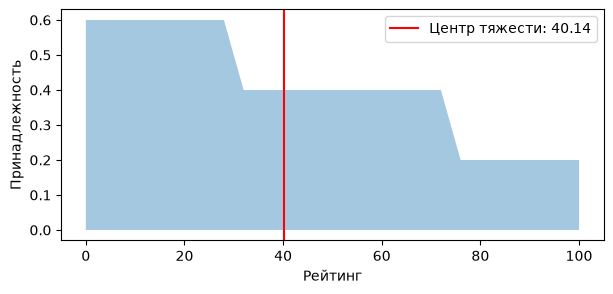

Активных правил: 8
Проверены границы, перекрытия, порядок оценок и отклонение неверных входов.


In [4]:
#| fig-cap: "Агрегированное выходное множество и центр тяжести"
rating, x, aggregate, active = mamdani(660,1.7,45)
fig, ax = plt.subplots(figsize=(7,3))
ax.fill_between(x, aggregate, alpha=0.4)
ax.axvline(rating, color="red", label=f"Центр тяжести: {rating:.2f}")
ax.set(xlabel="Рейтинг", ylabel="Принадлежность"); ax.legend(); plt.show()
print("Активных правил:",len(active))
assert len(active) > 1
assert 0 <= rating <= 100
assert mamdani(2700,5,40)[0] > mamdani(390,1,60)[0]
for name, (lo, hi) in domains.items():
    for value in [lo,hi]:
        inputs = dict(power=900,time=2.5,noise=47); inputs[name]=value
        assert np.isfinite(mamdani(**inputs)[0])
for bad in [-1,6001,float("nan")]:
    try: mamdani(bad,2,45)
    except ValueError: pass
    else: raise AssertionError("Некорректный вход принят")
print("Проверены границы, перекрытия, порядок оценок и отклонение неверных входов.")


# Выводы

Реализованы все стадии вывода Мамдани. В областях перекрытия одновременно активируются несколько правил, а результатом служит числовой рейтинг. Проверены граничные значения и некорректные входы. Рейтинг отражает выбранную учебную базу правил; для практического выбора оборудования нужна её экспертная калибровка.